# 02456 Deep Learning Project PINNs: Physics-informed neural networks Task 3: 1D Heat Equation

In [15]:
import time

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.optim as optim
import torch.nn.init as init

# double precision, as in project.ipynb (Task 2), so both notebooks compute in the same arithmetic
torch.set_default_dtype(torch.float64)

print("numpy", np.__version__, "| matplotlib", matplotlib.__version__, "| torch", torch.__version__)

numpy 2.0.2 | matplotlib 3.9.4 | torch 2.8.0


In [16]:
L_rod, T_end, alpha = 1.0, 1.0, 0.02
modes = [1, 2, 3, 4, 5]


def heat_exact(x, t, n):
    return np.sin(n * np.pi * x / L_rod) * np.exp(-alpha * (n * np.pi / L_rod)**2 * t)


x_grid = np.linspace(0, L_rod, 201)
t_grid = np.linspace(0, T_end, 201)
XX, TT = np.meshgrid(x_grid, t_grid)   # rows: time, columns: position

h = 1e-4
print(f"{'n':>2s} {'max |u_t - alpha u_xx| / max |u_t|':>36s} {'max |u(0,t)|, |u(L,t)|':>24s} {'max |u(x,0) - sin(n pi x/L)|':>30s}")
for n in modes:
    u_t = (heat_exact(XX, TT + h, n) - heat_exact(XX, TT - h, n)) / (2 * h)
    u_xx = (heat_exact(XX + h, TT, n) - 2 * heat_exact(XX, TT, n) + heat_exact(XX - h, TT, n)) / h**2
    pde = np.abs(u_t - alpha * u_xx).max() / np.abs(u_t).max()
    bc = max(np.abs(heat_exact(0.0, t_grid, n)).max(), np.abs(heat_exact(L_rod, t_grid, n)).max())
    ic = np.abs(heat_exact(x_grid, 0.0, n) - np.sin(n * np.pi * x_grid / L_rod)).max()
    print(f"{n:2d} {pde:36.1e} {bc:24.1e} {ic:30.1e}")

 n   max |u_t - alpha u_xx| / max |u_t|   max |u(0,t)|, |u(L,t)|   max |u(x,0) - sin(n pi x/L)|
 1                              1.2e-08                  1.2e-16                        0.0e+00
 2                              3.4e-08                  2.4e-16                        0.0e+00
 3                              7.9e-08                  3.7e-16                        0.0e+00
 4                              1.5e-07                  4.9e-16                        0.0e+00
 5                              2.5e-07                  6.1e-16                        0.0e+00


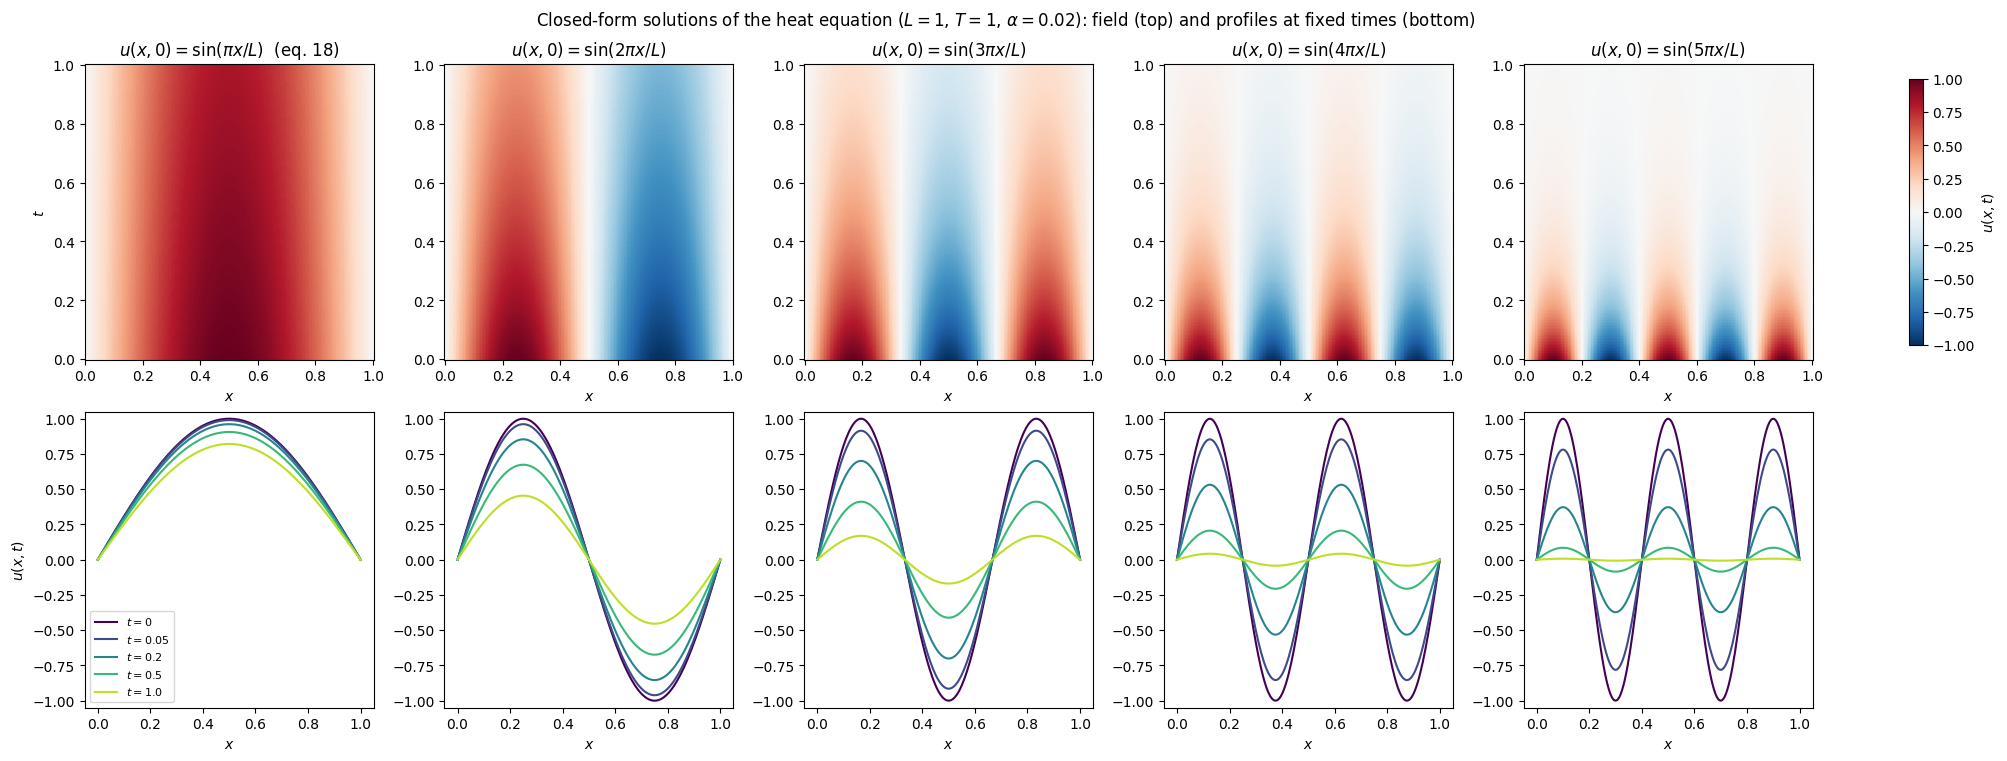

In [17]:
snap_times = [0, 0.05, 0.2, 0.5, 1.0]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(snap_times)))

fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), constrained_layout=True)
for j, n in enumerate(modes):
    im = axes[0, j].pcolormesh(x_grid, t_grid, heat_exact(XX, TT, n), cmap='RdBu_r', vmin=-1, vmax=1, shading='auto')
    axes[0, j].set_title('$u(x, 0) = \\sin(\\pi x / L)$  (eq. 18)' if n == 1 else f'$u(x, 0) = \\sin({n}\\pi x / L)$')
    axes[0, j].set_xlabel('$x$')
    for tk, col in zip(snap_times, colors):
        axes[1, j].plot(x_grid, heat_exact(x_grid, tk, n), color=col, label=f'$t = {tk}$')
    axes[1, j].set_ylim(-1.05, 1.05)
    axes[1, j].set_xlabel('$x$')
axes[0, 0].set_ylabel('$t$')
axes[1, 0].set_ylabel('$u(x, t)$')
axes[1, 0].legend(fontsize=8)
fig.colorbar(im, ax=axes[0, :], shrink=0.9, label='$u(x, t)$')
fig.suptitle(f'Closed-form solutions of the heat equation ($L = {L_rod:g}$, $T = {T_end:g}$, $\\alpha = {alpha:g}$): field (top) and profiles at fixed times (bottom)')
plt.show()

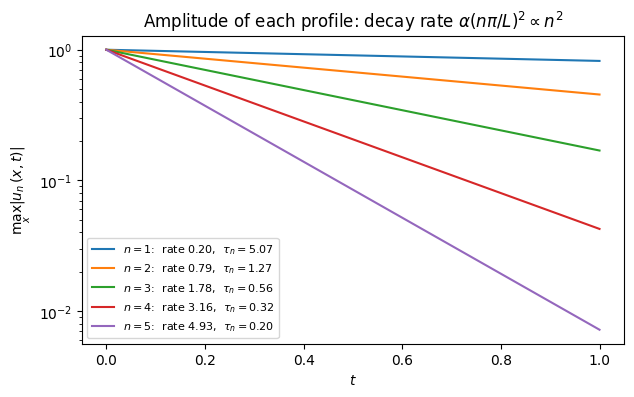

In [18]:
plt.figure(figsize=(7, 4))
for n in modes:
    rate = alpha * (n * np.pi / L_rod)**2
    plt.semilogy(t_grid, np.exp(-rate * t_grid), label=f'$n = {n}$:  rate {rate:.2f},  $\\tau_n = {1 / rate:.2f}$')
plt.xlabel('$t$')
plt.ylabel('$\\max_x |u_n(x, t)|$')
plt.title('Amplitude of each profile: decay rate $\\alpha (n\\pi / L)^2 \\propto n^2$')
plt.legend(fontsize=8)
plt.show()

In [19]:
def heat_residual(u_fn, x, t):
    x = x.clone().requires_grad_(True)
    t = t.clone().requires_grad_(True)
    u = u_fn(x, t)
    ones = torch.ones_like(u)
    u_t = torch.autograd.grad(u, t, ones, create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, ones, create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, ones, create_graph=True)[0]
    return u_t - alpha * u_xx


def heat_losses(u_fn, n, x_r, t_r, t_b, x_0):
    L_res = torch.mean(heat_residual(u_fn, x_r, t_r)**2)

    u_left = u_fn(torch.zeros_like(t_b), t_b)
    u_right = u_fn(torch.full_like(t_b, L_rod), t_b)
    L_bc = torch.mean(torch.cat([u_left, u_right])**2)

    u_init = u_fn(x_0, torch.zeros_like(x_0))
    L_ic = torch.mean((u_init - torch.sin(n * np.pi * x_0 / L_rod))**2)

    return L_res, L_bc, L_ic

In [20]:
def u_exact_torch(x, t, n, rate_factor=1.0):
    return torch.sin(n * np.pi * x / L_rod) * torch.exp(-rate_factor * alpha * (n * np.pi / L_rod)**2 * t)


x_check, t_check = torch.meshgrid(torch.linspace(0, L_rod, 52)[1:-1], torch.linspace(0, T_end, 51)[1:], indexing='ij')
x_r_check, t_r_check = x_check.reshape(-1, 1), t_check.reshape(-1, 1)
t_b_check = torch.linspace(0, T_end, 51).view(-1, 1)
x_0_check = torch.linspace(0, L_rod, 51).view(-1, 1)
check_points = (x_r_check, t_r_check, t_b_check, x_0_check)

print(f"{'candidate':34s} {'L_res':>10s} {'L_BC':>10s} {'L_IC':>10s}")
for n in modes:
    losses = heat_losses(lambda x, t: u_exact_torch(x, t, n), n, *check_points)
    print(f"{f'exact solution, n = {n}':34s} " + " ".join(f"{v.item():10.1e}" for v in losses))

n = 1
candidates = [("twice the decay rate, n = 1", lambda x, t: u_exact_torch(x, t, n, rate_factor=2.0)),
              ("trivial solution u = 0", lambda x, t: 0 * u_exact_torch(x, t, n)),
              ("exact + 0.1, n = 1", lambda x, t: u_exact_torch(x, t, n) + 0.1)]
for name, u_fn in candidates:
    losses = heat_losses(u_fn, n, *check_points)
    print(f"{name:34s} " + " ".join(f"{v.item():10.1e}" for v in losses))

candidate                               L_res       L_BC       L_IC
exact solution, n = 1                 3.1e-34    6.2e-33    0.0e+00
exact solution, n = 2                 3.0e-33    1.5e-32    0.0e+00
exact solution, n = 3                 8.6e-33    1.9e-32    0.0e+00
exact solution, n = 4                 1.1e-32    2.0e-32    0.0e+00
exact solution, n = 5                 1.5e-32    2.1e-32    0.0e+00
twice the decay rate, n = 1           1.4e-02    5.2e-33    0.0e+00
trivial solution u = 0                0.0e+00    0.0e+00    4.9e-01
exact + 0.1, n = 1                    3.1e-34    1.0e-02    1.0e-02


In [21]:
N_x, N_t = 40, 40
x_centres = (torch.arange(N_x) + 0.5) / N_x * L_rod
t_centres = (torch.arange(N_t) + 0.5) / N_t * T_end
x_r_grid, t_r_grid = torch.meshgrid(x_centres, t_centres, indexing='ij')
x_r, t_r = x_r_grid.reshape(-1, 1), t_r_grid.reshape(-1, 1)
t_b = torch.linspace(0, T_end, 40).view(-1, 1)
x_0 = torch.linspace(0, L_rod, 80).view(-1, 1)
heat_points = (x_r, t_r, t_b, x_0)

x_eval_heat = torch.from_numpy(XX.reshape(-1, 1))
t_eval_heat = torch.from_numpy(TT.reshape(-1, 1))

print(f"collocation points: {len(x_r)} | boundary points: 2 x {len(t_b)} | initial-condition points: {len(x_0)}")
print(f"evaluation grid: {XX.shape[1]} x {XX.shape[0]} = {len(x_eval_heat)} points")

collocation points: 1600 | boundary points: 2 x 40 | initial-condition points: 80
evaluation grid: 201 x 201 = 40401 points


In [22]:
class HeatNet(nn.Module):

    def __init__(self, num_hidden=32, num_layers=3):
        super(HeatNet, self).__init__()
        layers, num_in = [], 2
        for _ in range(num_layers):
            layers += [nn.Linear(num_in, num_hidden), nn.Tanh()]
            num_in = num_hidden
        layers.append(nn.Linear(num_in, 1))
        self.net = nn.Sequential(*layers)
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                init.xavier_normal_(layer.weight)
                init.constant_(layer.bias, 0)

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))


def heat_prediction(net):
    with torch.no_grad():
        return net(x_eval_heat, t_eval_heat).numpy().reshape(XX.shape)


def relative_l2(net, n):
    u_exact = heat_exact(XX, TT, n)
    return np.linalg.norm(heat_prediction(net) - u_exact) / np.linalg.norm(u_exact)


print("parameters per network:", sum(p.numel() for p in HeatNet().parameters()))

parameters per network: 2241


In [23]:
def train_heat_pinn(n, num_epochs=10000, lr=1e-3, lambdas=(1.0, 1.0, 1.0), seed=0, eval_every=100, print_every=2500,
                    num_hidden=32, num_layers=3):
    torch.manual_seed(seed)
    net = HeatNet(num_hidden, num_layers)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    lam_res, lam_bc, lam_ic = lambdas
    history = {"L": [], "L_res": [], "L_bc": [], "L_ic": [], "eval_epochs": [], "rel_l2": []}
    for epoch in range(num_epochs):
        if epoch % eval_every == 0:
            history["eval_epochs"].append(epoch)
            history["rel_l2"].append(relative_l2(net, n))
        if epoch == int(0.75 * num_epochs):
            for group in optimizer.param_groups:
                group['lr'] = lr / 10
        optimizer.zero_grad()
        L_res, L_bc, L_ic = heat_losses(net, n, *heat_points)
        L = lam_res * L_res + lam_bc * L_bc + lam_ic * L_ic
        L.backward()
        optimizer.step()
        for key, value in zip(["L", "L_res", "L_bc", "L_ic"], [L, L_res, L_bc, L_ic]):
            history[key].append(value.item())
        if print_every and epoch % print_every == 0:
            print(f"  n = {n}, epoch {epoch:5d}: L_res {L_res:.2e} | L_BC {L_bc:.2e} | L_IC {L_ic:.2e} | rel. L2 error {history['rel_l2'][-1]:.2e}")
    history["eval_epochs"].append(num_epochs)
    history["rel_l2"].append(relative_l2(net, n))
    return net, history

In [24]:
import time

heat_runs, heat_train_time = {}, {}
for n in modes:
    start = time.time()
    heat_runs[n] = train_heat_pinn(n)
    heat_train_time[n] = time.time() - start
    print(f"n = {n}: final rel. L2 error {heat_runs[n][1]['rel_l2'][-1]:.2e}, training time {heat_train_time[n]:.0f} s\n")

  n = 1, epoch     0: L_res 3.40e-03 | L_BC 9.90e-02 | L_IC 8.95e-01 | rel. L2 error 1.33e+00
  n = 1, epoch  2500: L_res 8.23e-05 | L_BC 2.32e-04 | L_IC 1.61e-04 | rel. L2 error 2.42e-02
  n = 1, epoch  5000: L_res 1.39e-05 | L_BC 2.93e-06 | L_IC 3.23e-06 | rel. L2 error 1.34e-03
  n = 1, epoch  7500: L_res 7.20e-06 | L_BC 8.59e-07 | L_IC 1.24e-06 | rel. L2 error 8.17e-04
n = 1: final rel. L2 error 7.40e-04, training time 62 s

  n = 2, epoch     0: L_res 3.40e-03 | L_BC 9.90e-02 | L_IC 4.25e-01 | rel. L2 error 9.20e-01
  n = 2, epoch  2500: L_res 4.46e-05 | L_BC 3.02e-06 | L_IC 5.03e-06 | rel. L2 error 1.48e-03
  n = 2, epoch  5000: L_res 1.75e-05 | L_BC 7.48e-07 | L_IC 1.58e-06 | rel. L2 error 7.62e-04
  n = 2, epoch  7500: L_res 1.01e-05 | L_BC 5.19e-07 | L_IC 8.96e-07 | rel. L2 error 6.19e-04
n = 2: final rel. L2 error 5.45e-04, training time 62 s

  n = 3, epoch     0: L_res 3.40e-03 | L_BC 9.90e-02 | L_IC 6.77e-01 | rel. L2 error 1.34e+00
  n = 3, epoch  2500: L_res 4.67e-04 | L

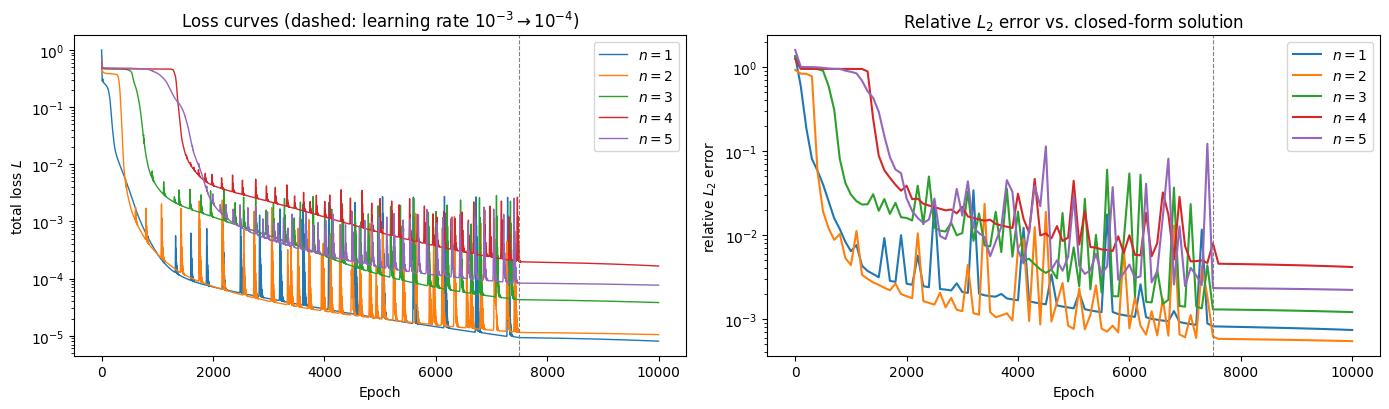

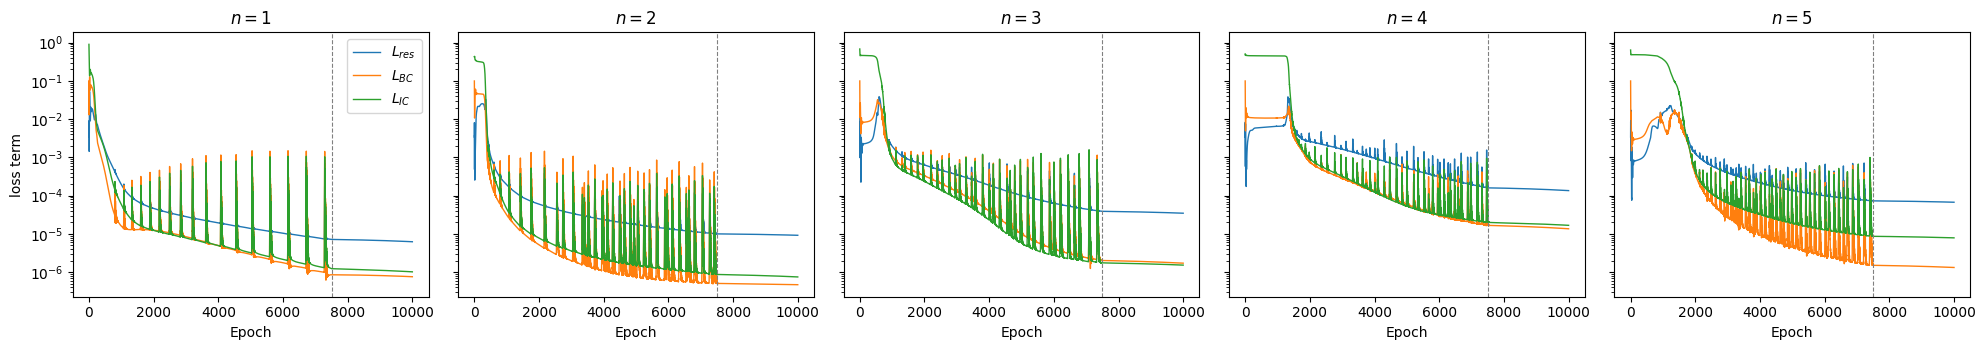

 n      L_res       L_BC       L_IC  rel. L2 error  max |error|
 1   6.26e-06   7.64e-07   1.03e-06       7.40e-04     2.80e-03
 2   9.23e-06   4.73e-07   7.54e-07       5.45e-04     2.76e-03
 3   3.48e-05   1.73e-06   1.54e-06       1.21e-03     3.34e-03
 4   1.36e-04   1.36e-05   1.68e-05       4.15e-03     9.91e-03
 5   6.74e-05   1.33e-06   7.91e-06       2.22e-03     6.12e-03


In [25]:
switch_epoch = int(0.75 * len(heat_runs[1][1]["L"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
for n in modes:
    hist = heat_runs[n][1]
    ax1.semilogy(hist["L"], lw=1, label=f'$n = {n}$')
    ax2.semilogy(hist["eval_epochs"], hist["rel_l2"], label=f'$n = {n}$')
for ax in (ax1, ax2):
    ax.axvline(switch_epoch, color='grey', ls='--', lw=0.8)
    ax.set_xlabel('Epoch')
    ax.legend()
ax1.set_ylabel('total loss $L$')
ax1.set_title('Loss curves (dashed: learning rate $10^{-3} \\to 10^{-4}$)')
ax2.set_ylabel('relative $L_2$ error')
ax2.set_title('Relative $L_2$ error vs. closed-form solution')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6), sharey=True)
for ax, n in zip(axes, modes):
    hist = heat_runs[n][1]
    ax.semilogy(hist["L_res"], lw=1, label='$L_{res}$')
    ax.semilogy(hist["L_bc"], lw=1, label='$L_{BC}$')
    ax.semilogy(hist["L_ic"], lw=1, label='$L_{IC}$')
    ax.axvline(switch_epoch, color='grey', ls='--', lw=0.8)
    ax.set_title(f'$n = {n}$')
    ax.set_xlabel('Epoch')
axes[0].set_ylabel('loss term')
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"{'n':>2s} {'L_res':>10s} {'L_BC':>10s} {'L_IC':>10s} {'rel. L2 error':>14s} {'max |error|':>12s}")
for n in modes:
    net_n, hist = heat_runs[n]
    max_err = np.abs(heat_prediction(net_n) - heat_exact(XX, TT, n)).max()
    print(f"{n:2d} {hist['L_res'][-1]:10.2e} {hist['L_bc'][-1]:10.2e} {hist['L_ic'][-1]:10.2e} {hist['rel_l2'][-1]:14.2e} {max_err:12.2e}")

In [26]:
early = TT <= 0.05
edges = ~early & ((XX <= 0.05) | (XX >= L_rod - 0.05))
interior = ~early & ~edges

print(f"{'n':>2s} {'epochs L>0.3':>12s} {'max err 2500-7499':>18s} {'err at 7500':>12s} {'final err':>10s} "
      f"{'L(9000)/L_end':>14s} {'err(9000)/err_end':>18s} {'RMS t<=0.05':>12s} {'RMS ends':>9s} {'RMS rest':>9s}")
for n in modes:
    net_n, hist = heat_runs[n]
    L = np.array(hist["L"])
    ep, err = np.array(hist["eval_epochs"]), np.array(hist["rel_l2"])
    sq = (heat_prediction(net_n) - heat_exact(XX, TT, n))**2
    rms = {name: np.sqrt(sq[mask].mean()) for name, mask in [("early", early), ("edges", edges), ("interior", interior)]}
    print(f"{n:2d} {(L > 0.3).sum():12d} {err[(ep >= 2500) & (ep < 7500)].max():18.1e} {err[ep == 7500][0]:12.1e} {err[-1]:10.1e} "
          f"{L[9000] / L[-1]:14.2f} {err[ep == 9000][0] / err[-1]:18.2f} {rms['early']:12.1e} {rms['edges']:9.1e} {rms['interior']:9.1e}")

 n epochs L>0.3  max err 2500-7499  err at 7500  final err  L(9000)/L_end  err(9000)/err_end  RMS t<=0.05  RMS ends  RMS rest
 1           17            3.4e-02      8.2e-04    7.4e-04           1.08               1.05      9.4e-04   5.4e-04   4.2e-04
 2          309            2.3e-02      6.2e-04    5.4e-04           1.05               1.03      6.7e-04   4.3e-04   1.9e-04
 3          571            6.0e-02      1.3e-03    1.2e-03           1.06               1.04      9.7e-04   8.0e-04   3.1e-04
 4         1335            4.6e-02      8.0e-03    4.2e-03           1.10               1.05      2.9e-03   2.3e-03   6.4e-04
 5         1134            1.2e-01      2.3e-03    2.2e-03           1.05               1.03      1.6e-03   7.3e-04   2.7e-04


In [27]:
start = time.time()
net_1layer, history_1layer = train_heat_pinn(5, num_hidden=560, num_layers=1, print_every=0)
time_1layer = time.time() - start
for name, net_, hist in [("1 hidden layer x 560", net_1layer, history_1layer), ("3 hidden layers x 32", *heat_runs[5])]:
    print(f"{name:22s} ({sum(p.numel() for p in net_.parameters())} parameters): rel. L2 error {hist['rel_l2'][-1]:.2e} | "
          f"L_res {hist['L_res'][-1]:.1e} | L_BC {hist['L_bc'][-1]:.1e} | L_IC {hist['L_ic'][-1]:.1e} | "
          f"epochs with L > 0.3: {(np.array(hist['L']) > 0.3).sum()}")
print(f"(single-layer training time {time_1layer:.0f} s)")

1 hidden layer x 560   (2241 parameters): rel. L2 error 9.06e-01 | L_res 1.3e-02 | L_BC 9.7e-03 | L_IC 4.1e-01 | epochs with L > 0.3: 10000
3 hidden layers x 32   (2241 parameters): rel. L2 error 2.22e-03 | L_res 6.7e-05 | L_BC 1.3e-06 | L_IC 7.9e-06 | epochs with L > 0.3: 1134
(single-layer training time 154 s)


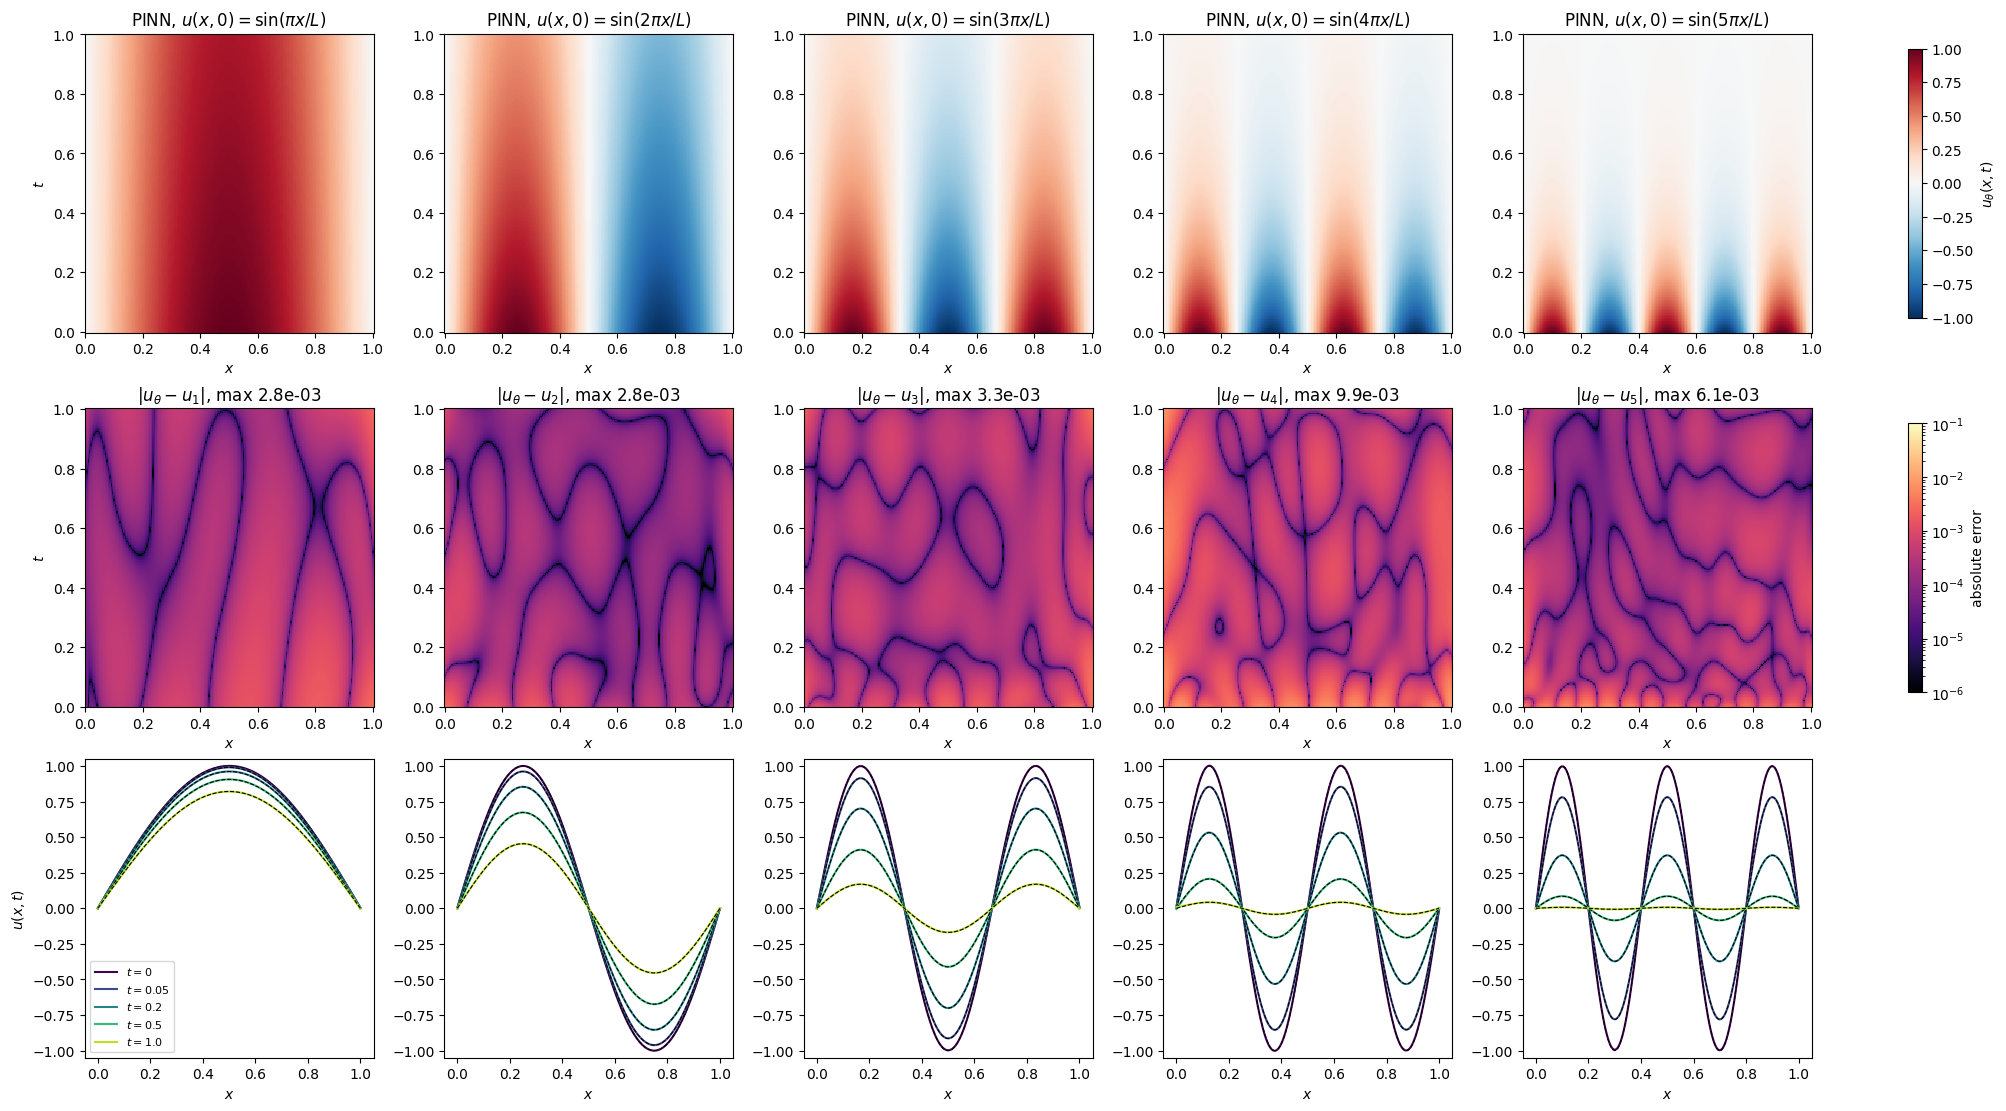

In [28]:
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(3, 5, figsize=(20, 11), constrained_layout=True)
for j, n in enumerate(modes):
    u_pinn = heat_prediction(heat_runs[n][0])
    err = np.abs(u_pinn - heat_exact(XX, TT, n))
    im0 = axes[0, j].pcolormesh(x_grid, t_grid, u_pinn, cmap='RdBu_r', vmin=-1, vmax=1, shading='auto')
    im1 = axes[1, j].pcolormesh(x_grid, t_grid, np.maximum(err, 1e-7), cmap='magma', norm=LogNorm(vmin=1e-6, vmax=1e-1), shading='auto')
    axes[0, j].set_title(f'PINN, $u(x, 0) = \\sin({n}\\pi x / L)$' if n > 1 else 'PINN, $u(x, 0) = \\sin(\\pi x / L)$')
    axes[1, j].set_title(f'$|u_\\theta - u_{n}|$, max {err.max():.1e}')
    for tk, col in zip(snap_times, colors):
        k = int(np.argmin(np.abs(t_grid - tk)))
        axes[2, j].plot(x_grid, u_pinn[k], color=col, label=f'$t = {tk}$')
        axes[2, j].plot(x_grid, heat_exact(x_grid, tk, n), color='k', ls='--', lw=0.8)
    axes[2, j].set_ylim(-1.05, 1.05)
    for i in range(3):
        axes[i, j].set_xlabel('$x$')
for i, label in enumerate(['$t$', '$t$', '$u(x, t)$']):
    axes[i, 0].set_ylabel(label)
axes[2, 0].legend(fontsize=8)
fig.colorbar(im0, ax=axes[0, :], shrink=0.9, label='$u_\\theta(x, t)$')
fig.colorbar(im1, ax=axes[1, :], shrink=0.9, label='absolute error')
plt.show()